![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 01 | EDA and Baseline

*Project 2 — Machine Learning: From Data to Predictions*

**Team:** Jovana Krstevska
**Dataset:** Telco Customer Churn (IBM sample), Apache 2.0 licence

---

Steps 1 to 4 of the workflow: frame the problem, look at the data, split once, and score the baseline every model will have to beat.

> **Done when:** your framing is written down, you know what is broken in the data and which columns must go, the split is fixed, and you have a baseline score from cross-validation.

The sections below are a suggested route, not a form to fill in. Add sections, drop them, reorder them — what is graded is the work, not whether you kept the scaffold.

---
## 0. Setup

In [1]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.functions import *

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

---
## 1. Frame the problem

Before any code. In a few sentences:

- **The question:** who or what you predict, for whom, and what they would do with the prediction.
- **The target**, and for classification **the positive class**.
- **The metric**, and why: which mistake costs more?

You wrote a first version on launch day. Update it here as the data teaches you things.

## Problem:
- **Question**: Predict which current customers are likely to churn, so the retention team can contact them with an offer. 
- **Target**: Churn, positive class = “Yes.” 
- **Metrics**: F2 (primary), with average precision, recall, precision and % flagged as supporting metrics. 
- The user is the retention team. The decision: who gets a call or offer this month.
- A churner pays about €74/month, so losing one costs about €900 a year. A retention offer costs about €50. Missing a churner is therefore about 18× worse than a wasted offer, which is why we weight recall heavily and use F2.

---
## 2. Load the raw data

Run `python download_data.py <houses|telco|bank|flowers>` from the repo root first. Your files land in `data/raw/`, which is gitignored.

In [2]:
telco = load_data()
df = telco.copy()

---
## 3. First look

Shape, column types, a handful of rows. What is one row of this data, and what is the target column?

In [3]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.40,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.90,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,Yes,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [4]:
print(f"Data shape, rows: {df.shape[0]}, columns: {df.shape[1]}\n")
print(f"Columns Types: \n{df.dtypes}\n")
print(f"Columns Types Overall: \n{df.dtypes.value_counts()}")

Data shape, rows: 7043, columns: 21

Columns Types: 
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

Columns Types Overall: 
str        17
int64       2
float64     2
Name: count, dtype: int64


## Initial Findings:
- The data has 7043 rows and 21 columns
- The target column is - `Churn`: `Yes`/`No`
- Most of the columns are categorical. Only numercial columns are: `SeniorCitizen`, `tenure`, `MonthlyCharges`. 
- Column `TotalCharges` is shown as a str, which is unsual for a column that should clearly be numerical. Keep it as a flag and check below whether there's empty values.

---
## 4. Data quality

Missing values (including ones in disguise, such as `"unknown"`, blanks or `999`), duplicates, numbers stored as text, dates stored as strings. Write down what you find and what you will do about it.

In [5]:
# Unique values
print(f"Number of unique values in each column: \n{df.nunique()}")

Number of unique values in each column: 
customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64


In [6]:
col_unique_vals = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
for col in col_unique_vals:
    print(f"{col} ({df[col].nunique()} unique values):")
    print(df[col].value_counts())

gender (2 unique values):
gender
Male      3555
Female    3488
Name: count, dtype: int64
SeniorCitizen (2 unique values):
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64
Partner (2 unique values):
Partner
No     3641
Yes    3402
Name: count, dtype: int64
Dependents (2 unique values):
Dependents
No     4933
Yes    2110
Name: count, dtype: int64
tenure (73 unique values):
tenure
1     613
72    362
2     238
3     200
4     176
     ... 
28     57
39     56
44     51
36     50
0      11
Name: count, Length: 73, dtype: int64
PhoneService (2 unique values):
PhoneService
Yes    6361
No      682
Name: count, dtype: int64
MultipleLines (3 unique values):
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
InternetService (3 unique values):
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
OnlineSecurity (3 unique values):
OnlineSecurity
No                     3498
Yes

In [7]:
# Missing values
print(f"Missing values: \n{df.isnull().sum().sum()}")

Missing values: 
0


In [8]:
# Check col TotalCharges and change it to numerical, then fill missing values with 0
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].isna().sum())
print(df.loc[df["TotalCharges"].isna(), "tenure"].unique())
df["TotalCharges"] = df["TotalCharges"].fillna(0)     

0
[]


In [9]:
# Duplicate values without customer ID, because it is unique
print(f"Duplicate values: \n{df.drop(columns='customerID').duplicated().sum()}")

Duplicate values: 
22


## Data Quality Findings:

- Column: `TotalCharges` has been cas to numeric, and there were 11 missing values, that were filled with 0, because these were new clients where tenure = 0.
- Columns: `gender`, `SeniorCitizen`, `Partner`, `Dependents`, `PhoneService`, `PaperlessBilling` are all boolean `Yes`/`No` and can be binary encoded, i.e. as `1`/`0`.
- `MultipleLines` contains "No phone service" (682 rows), identical to `PhoneService == "No"`; the ('MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies') internet add-on columns contain "No internet service" (1526 rows each), identical to `InternetService == "No"`. We keep these as a separate category rather than merging them into "No", so that "No" only means "has the service but not this add-on". They will be one-hot encoded in notebook 02.
- `customerID` will be dropped in the next step as it's an identifier.
- Found 22 duplicates. Each one has a different customerID, so they are most likely different customers with the same simple profile therefore they will not be removed.

---
## 5. Columns that must go

Identifiers, and **anything that would not be known at the moment you make a prediction**. List them with the reason. A column that looks too good to be true usually is.

In [10]:
# Drop customer ID it's a unique identifier 
df = df.drop(columns=['customerID'])

Every remaining column is known at the moment making the prediction. For churners, tenure is “months until they left”, while for current customers it’s “months so far”. This makes tenure look more predictive in this case. 

---
## 6. The target

Its distribution. For classification, the share of each class: this is what makes accuracy honest or misleading. For regression, is it skewed?

In [11]:
target = df['Churn']
pd.DataFrame({
    "count": target.value_counts(),
    "share": target.value_counts(normalize=True).round(3)
})

,count,share
Churn,,
No,5174,0.735
Yes,1869,0.265


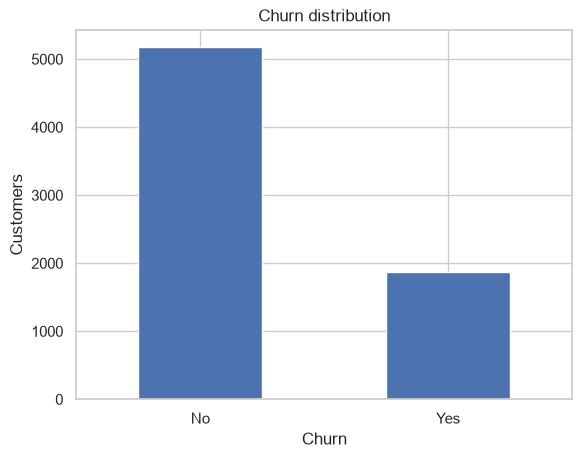

In [12]:
# Bar plot visualizing the Churns
ax = target.value_counts().plot(kind="bar", rot=0)
ax.set_title("Churn distribution")
ax.set_ylabel("Customers")
plt.show()

## Target Findings:
- The target is imbalanced: about 73% of customers stayed (`No`), 27% churned (`Yes`).
- A model that always predicts "No" would already reach ~73% accuracy while catching zero churners, so accuracy is misleading here.
- For evaluation, metrics: recall and F2 will be used, a stratified split and stratified cross-validation to keep the 73/27 ratio in every fold.
- The imbalance is moderate, not extreme, so it's not resampled. If needed, `class_weight="balanced"` will be used in notebook 02.

---
## 7. Features against the target

Which features move with the target, and how? Numeric against target, categories against target. Write the takeaway under each chart.

In [13]:
# Numeric features distribution
num_columns = ['tenure', 'MonthlyCharges', 'TotalCharges']
df[num_columns].describe().T.sort_values("mean", ascending=False).round(2)


,count,mean,std,min,25%,50%,75%,max
TotalCharges,7043.0,2279.73,2266.79,0.00,398.55,1394.55,3786.60,8684.80
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00


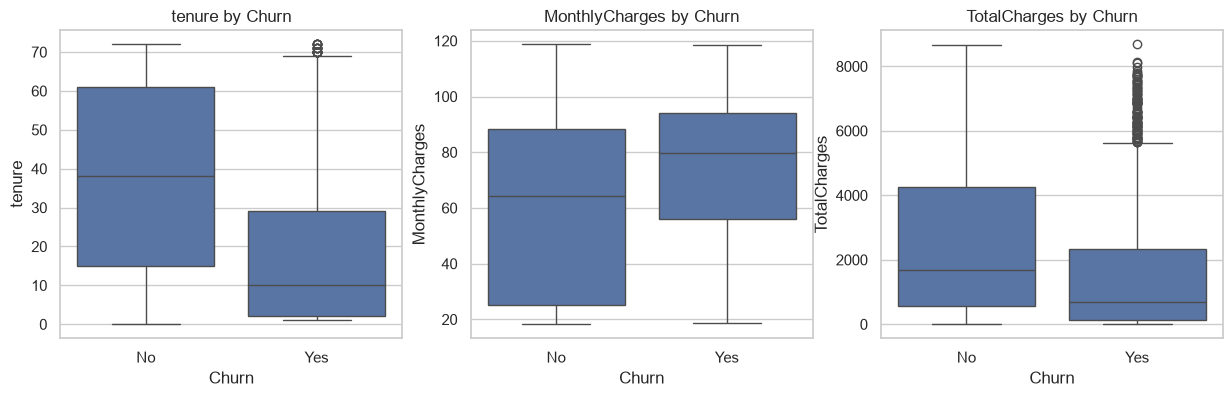

In [14]:
# Numeric features vs. target -- tenure, MonthlyCharges, TotalCharges. Compare their distributions for churners and non-churners.

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(data=df, x="Churn", y=col, ax=ax)
    ax.set_title(f"{col} by Churn")
plt.show()

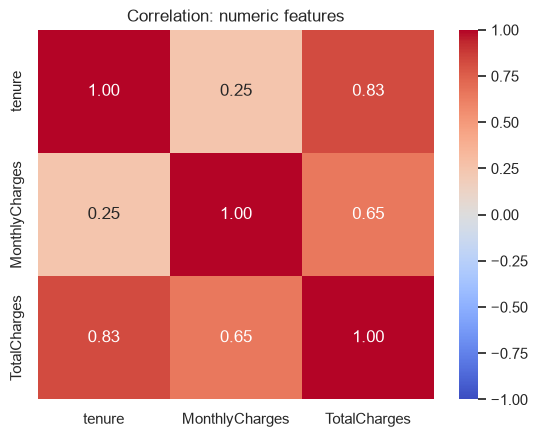

In [15]:
corr = df[num_columns].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation: numeric features")
plt.show()

**Numeric vs. target features:**
- **`tenure`**: strongest numeric signal. Churners have a median tenure of ~10 months vs. ~38 for non-churners, meaning that most churns happen within the first two years.
- **`MonthlyCharges`**: churners pay more (median ~80 vs. ~65). Customers with lower-cost plans churn significantly less.
- **`TotalCharges`**: lower for churners (median ~700 vs. ~1,700) despite higher monthly charges, because it largely reflects tenure, TotalCharges = tenure * Monthly charges.
- `tenure` and `TotalCharges` are strongly correlated (0.83).
- The outliers among churners in `tenure` and `TotalCharges` are most likely long-term customers who left.

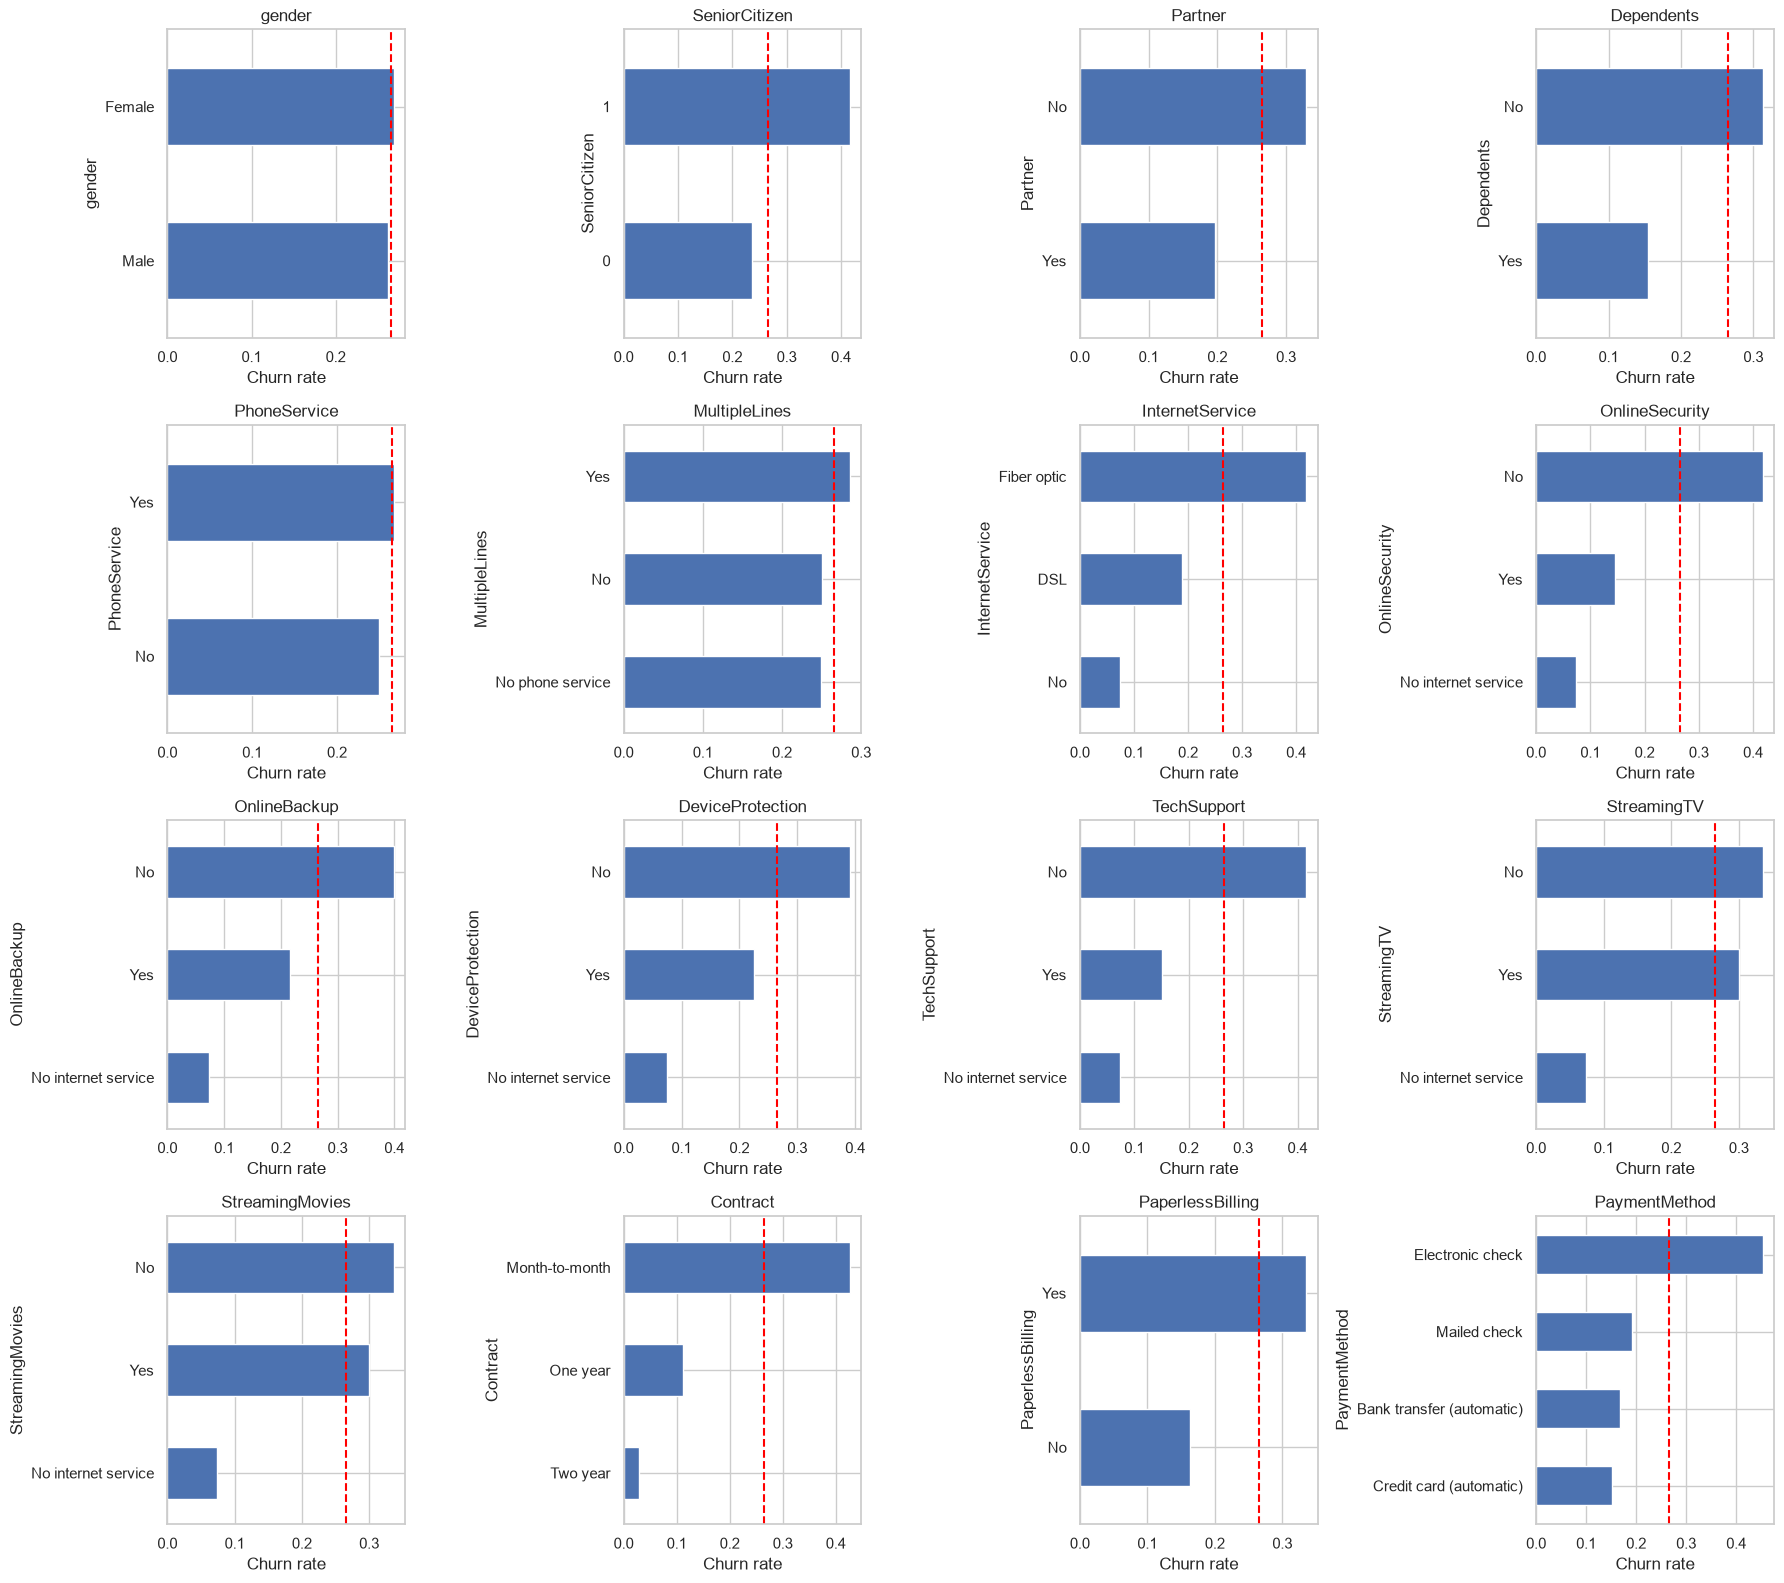

In [16]:
# Categorical features vs. target
cat_cols = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',	'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

churn_flag = (df["Churn"] == "Yes").astype(int)
overall = churn_flag.mean()

fig, axes = plt.subplots(4, 4, figsize=(18, 16))
for ax, col in zip(axes.flat, cat_cols):
    rates = churn_flag.groupby(df[col]).mean().sort_values()
    rates.plot(kind="barh", ax=ax)
    ax.axvline(overall, color="red", linestyle="--", label='overall churn rate')
    ax.set_title(col)
    ax.set_xlabel("Churn rate")

plt.tight_layout()
plt.show()

**Categorical vs. target features**
- **Strongest signals:** `Contract` (month-to-month ~45% churn vs. ~5% for two-year), `InternetService` (fiber ~45%, DSL ~20%, none ~8%), `PaymentMethod` (electronic check ~45% vs. 15–20% for the others), and `OnlineSecurity` and `TechSupport` (~45% without vs. ~15% with).
- **Moderate signals:** `OnlineBackup`, `DeviceProtection`, `SeniorCitizen`, `Dependents`, `Partner`, `PaperlessBilling`.
- **Little or no signal:** `gender`, `PhoneService`, `MultipleLines`, `StreamingTV`, `StreamingMovies`. Churn rates are close to the overall rate in every category.
- Customers without internet churn least (~7%), which pulls the overall rate down. For the add-ons, the meaningful comparison is "Yes" vs. "No" among internet customers.

---
## 8. Split once

A fixed `random_state`, stratified for classification. From here on, everything happens on the training set; the test set waits until notebook 03.

In [17]:
from sklearn.model_selection import train_test_split

In [18]:
# Split between train and test data and stratify

X_train, X_test, y_train, y_test = split_data(df)

print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(5634, 19) (1409, 19)
0.265 0.265


- Stratified 80/20 split with `random_state=0`: 5634 training rows, 1409 test rows.
- Churn rate is 26.5% in both sets.

---
## 9. Baseline

A `DummyClassifier` or `DummyRegressor`, scored with the cross-validation you will use for every model. Write the number down: it is what next week's models have to beat.

In [19]:
# We predict churn in this dataset, therefore we use a DummyClassifier

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

In [20]:
# Baseline Models
baselines = {
    'Always "No"': DummyClassifier(strategy="most_frequent"),
    'Always "Yes"': DummyClassifier(strategy="constant", constant=1),
}

rows = []
for name, model in baselines.items():
    res = cross_validate(model, X_train, y_train, cv=CV, scoring=SCORING)
    row = {"baseline": name}
    for metric in SCORING:
        row[metric] = res[f"test_{metric}"].mean()
    rows.append(row)

baseline_table = pd.DataFrame(rows).set_index("baseline").round(3)
baseline_table

,f2,average_precision,recall,precision,f1,accuracy
baseline,,,,,,
"Always ""No""",0.000,0.265,0.0,0.000,0.000,0.735
"Always ""Yes""",0.644,0.265,1.0,0.265,0.419,0.265


## Dummy Score
Baselines: two dummy classifiers, scored with the same 5-fold stratified CV used for every model:

Always “No” reaches 73.5% accuracy but catches no churners (recall 0, F2 0). Accuracy is therefore not used.
Always “Yes” catches every churner (recall 1.0) but contacts every customer (precision 0.265), giving F2 = 0.64. Recall alone is therefore not used either.

Metric. The primary metric is F2, which weights recall above precision because missing a churner costs more than an unnecessary retention offer, while still penalising flagging everyone. The bar to beat is F2 = 0.64 and average precision 0.265.

---
## 10. Into notebook 02

The columns you keep and how each type will be prepared, the features you want to try, and the models you will compare.

- Numeric columns: impute with median and scale. 
- Categorical columns: one-hot encoding and keeping “No internet service”. 
- Features to try: n_addons (add-ons lower churn), new_customer (churn is concentrated early in tenure), con_serv (month-to-month + fiber are both high-risk). 
- Models: linear, KNN, SVM, tree, random forest, gradient boosting. 
- class_weight="balanced" because of the 73/27 split.